In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

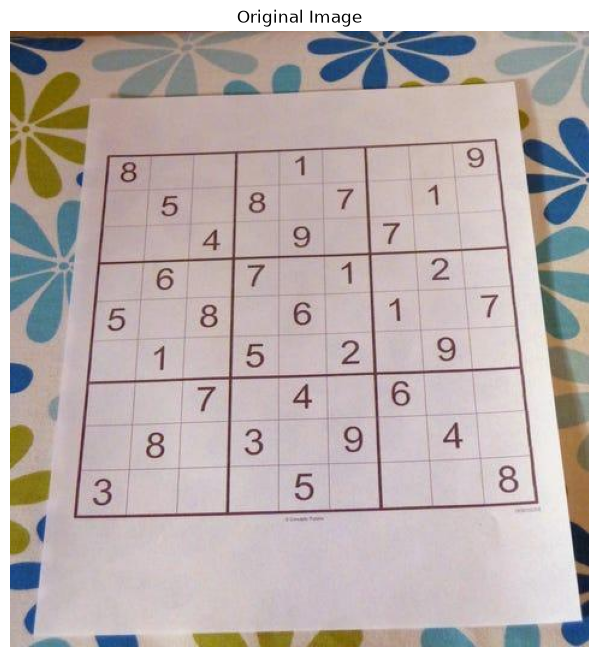

In [2]:
image_path = "data/img1.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

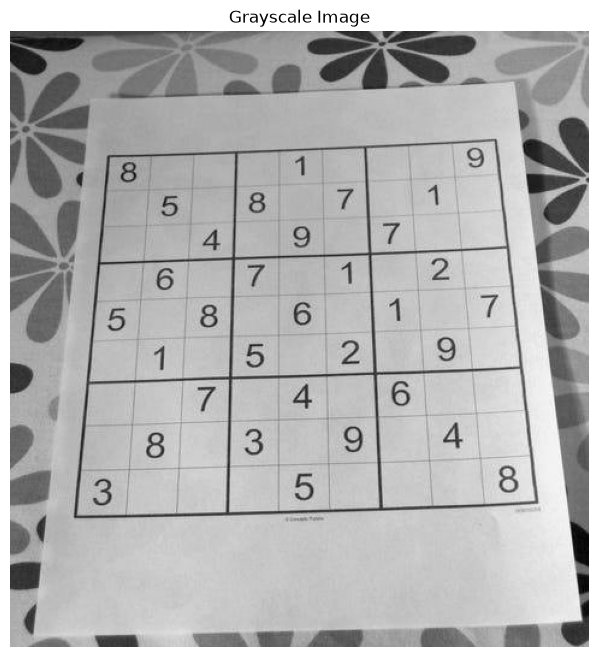

In [3]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 8))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

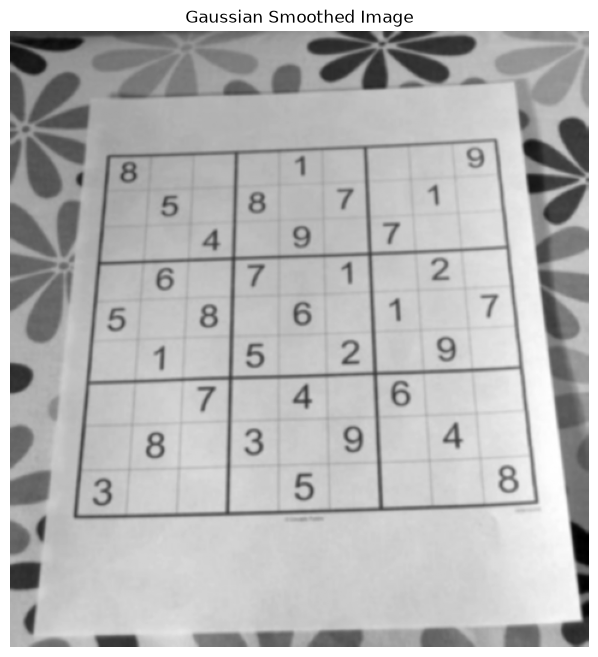

In [4]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

plt.figure(figsize=(8, 8))
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Smoothed Image")
plt.axis("off")
plt.show()

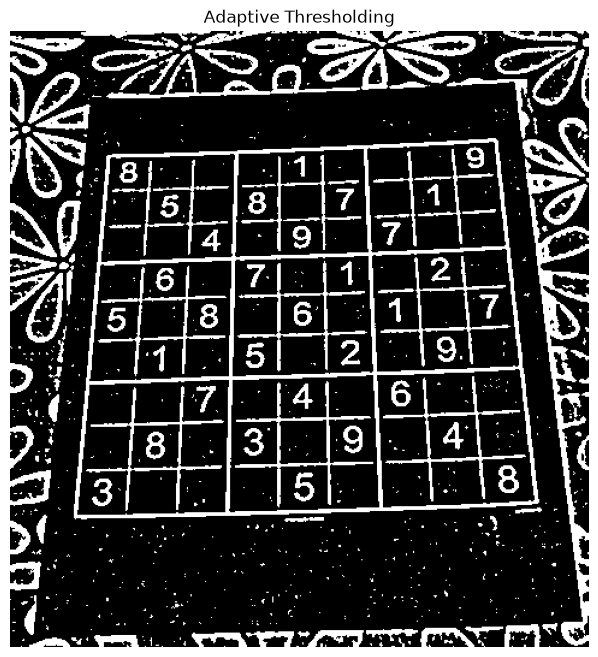

In [5]:
thresholded = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11,2)

plt.figure(figsize=(8, 8))
plt.imshow(thresholded, cmap="gray")
plt.title("Adaptive Thresholding")
plt.axis("off")
plt.show()

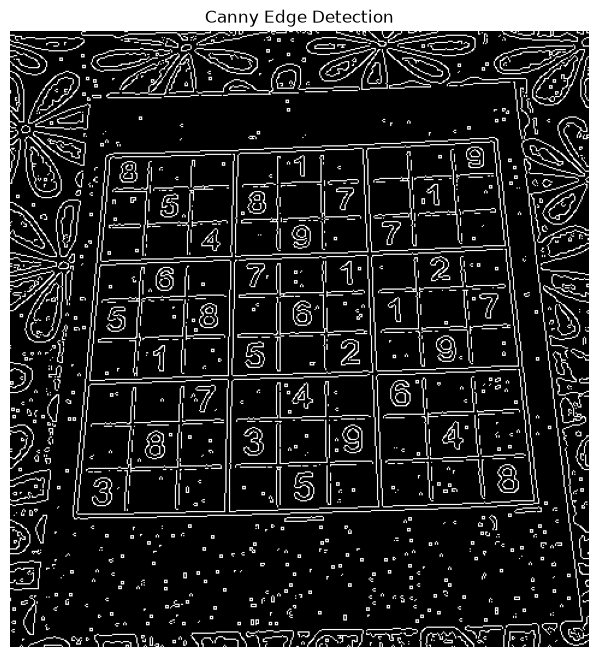

In [6]:
edges = cv2.Canny(thresholded, 50, 150)

plt.figure(figsize=(8, 8))
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

Number of detected lines: 111


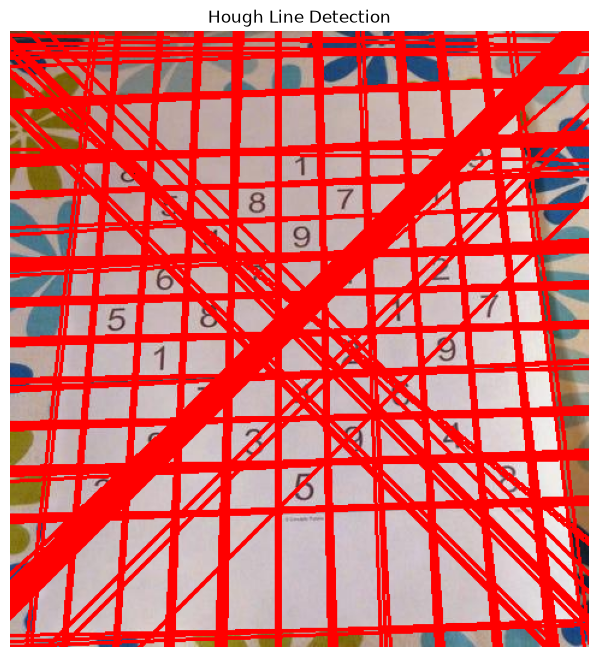

In [7]:
lines = cv2.HoughLines(edges, 1, np.pi / 180, 120)

hough_image = image.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 2000 * (-b))
        y1 = int(y0 + 2000 * a)
        x2 = int(x0 - 2000 * (-b))
        y2 = int(y0 - 2000 * a)
        cv2.line(hough_image, (x1, y1), (x2, y2), (0, 0, 255), 2)
    print("Number of detected lines:", len(lines))
else:
    print("No lines detected")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(hough_image, cv2.COLOR_BGR2RGB))
plt.title("Hough Line Detection")
plt.axis("off")
plt.show()

In [8]:
horizontal_lines = []
vertical_lines = []

if lines is None:
    raise ValueError("No Hough lines detected")
for line in lines:
    rho, theta = line[0]
    angle = np.degrees(theta)
    if angle < 30 or angle > 150:
        vertical_lines.append((rho, theta))
    elif 60 < angle < 120:
        horizontal_lines.append((rho, theta))
print("Horizontal lines:", len(horizontal_lines))
print("Vertical lines:", len(vertical_lines))

Horizontal lines: 52
Vertical lines: 33


In [9]:
contours, _ = cv2.findContours(thresholded.copy(),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

largest_contour = max(contours, key=cv2.contourArea)
perimeter = cv2.arcLength(largest_contour, True)
approx = cv2.approxPolyDP(largest_contour,0.02 * perimeter,True)

if len(approx) != 4:
    raise ValueError("Could not locate the four grid boundaries")

points = approx.reshape(4, 2)

point_sum = points.sum(axis=1)
point_diff = np.diff(points, axis=1).flatten()

tl = points[np.argmin(point_sum)]
tr = points[np.argmin(point_diff)]
br = points[np.argmax(point_sum)]
bl = points[np.argmax(point_diff)]

def closest_line(p1, p2):
    best_line = None
    min_error = float("inf")

    for line in lines:
        rho, theta = line[0]

        normal = np.array([np.cos(theta),np.sin(theta)])

        d1 = abs(np.dot(p1, normal) - rho)
        d2 = abs(np.dot(p2, normal) - rho)

        error = (d1 + d2) / 2

        if error < min_error:
            min_error = error
            best_line = (rho, theta)

    return best_line

left = closest_line(tl, bl)
right = closest_line(tr, br)
top = closest_line(tl, tr)
bottom = closest_line(bl, br)

In [10]:
def intersection(line1, line2):
    rho1, theta1 = line1
    rho2, theta2 = line2

    A = np.array([[np.cos(theta1), np.sin(theta1)],[np.cos(theta2), np.sin(theta2)]])

    B = np.array([rho1, rho2])

    x, y = np.linalg.solve(A, B)

    return [x, y]


top_left = intersection(top, left)
top_right = intersection(top, right)
bottom_right = intersection(bottom, right)
bottom_left = intersection(bottom, left)

corners = np.array([top_left,top_right,bottom_right,bottom_left], dtype=np.float32)

print("Detected corners:")
print(corners)

Detected corners:
[[ 79.38677  102.291756]
 [405.7238    90.89581 ]
 [437.1589   389.98093 ]
 [ 53.043697 403.39453 ]]


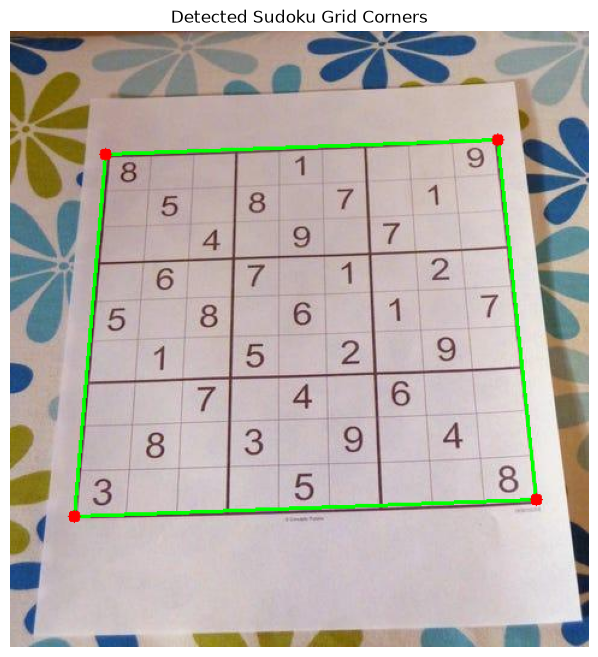

In [11]:
corner_image = image.copy()
cv2.polylines(corner_image,[corners.astype(np.int32)],True,(0, 255, 0),2)

for x, y in corners:
    cv2.circle(corner_image,(int(x), int(y)),5,(0, 0, 255),-1)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(corner_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Sudoku Grid Corners")
plt.axis("off")
plt.show()

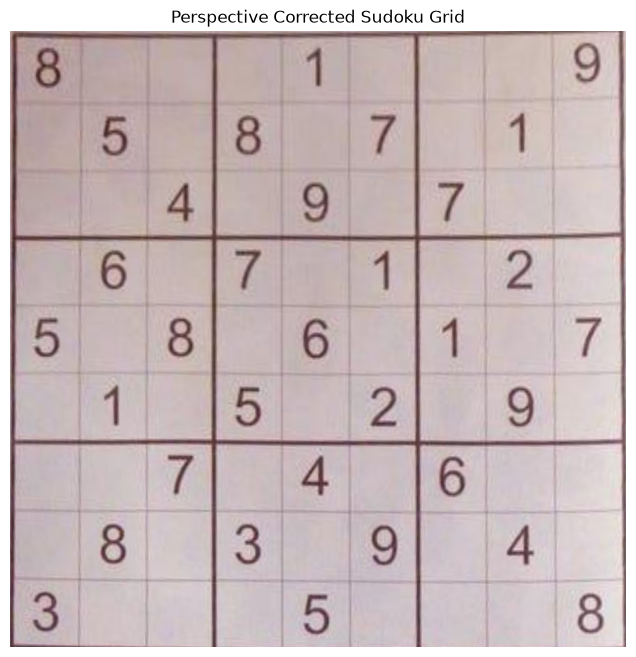

In [12]:
grid_size = 900

destination_corners = np.array([[0, 0],[grid_size - 1, 0],[grid_size - 1, grid_size - 1],[0, grid_size - 1]], dtype=np.float32)

matrix = cv2.getPerspectiveTransform(corners, destination_corners)

warped = cv2.warpPerspective(image, matrix,(grid_size, grid_size))

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
plt.title("Perspective Corrected Sudoku Grid")
plt.axis("off")
plt.show()

In [13]:
cell_size = grid_size // 9

cells = []

for row in range(9):
    for col in range(9):

        y_start = row * cell_size
        y_end = (row + 1) * cell_size

        x_start = col * cell_size
        x_end = (col + 1) * cell_size

        cell = warped[y_start:y_end, x_start:x_end]

        cells.append(cell)

print("Number of extracted cells:", len(cells))
print("Cell dimensions:", cells[0].shape)

Number of extracted cells: 81
Cell dimensions: (100, 100, 3)


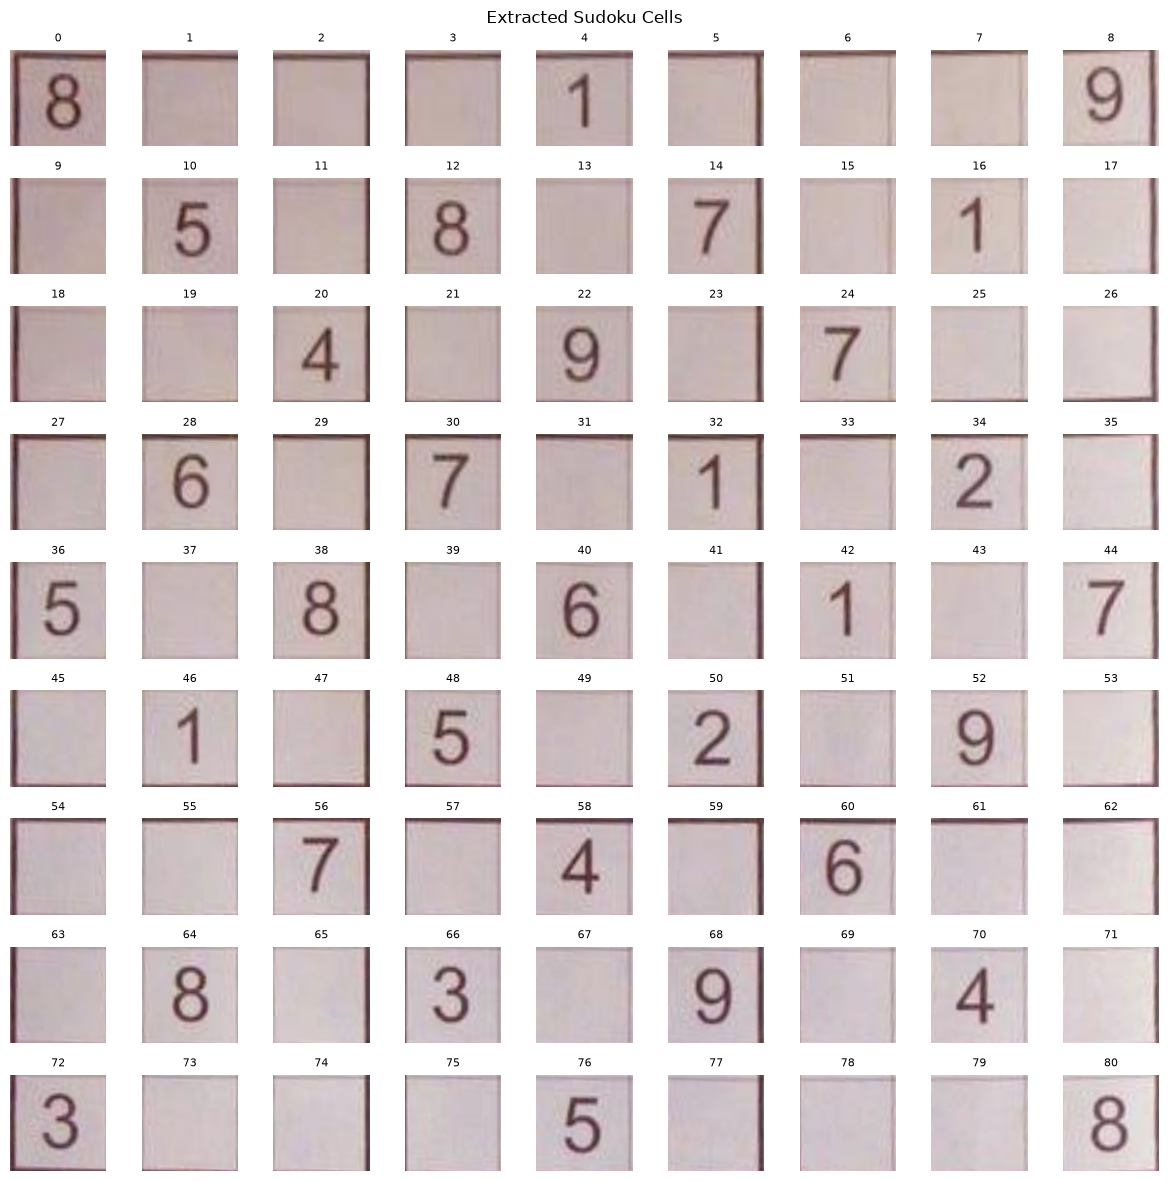

In [14]:
fig, axes = plt.subplots(9, 9, figsize=(12, 12))

for i in range(81):

    row = i // 9
    col = i % 9

    axes[row, col].imshow(
        cv2.cvtColor(cells[i], cv2.COLOR_BGR2RGB)
    )

    axes[row, col].set_title(str(i), fontsize=8)
    axes[row, col].axis("off")

plt.suptitle("Extracted Sudoku Cells")
plt.tight_layout()
plt.show()

In [15]:
binary_cells = []

for cell in cells:
    gray_cell = cv2.cvtColor(cell, cv2.COLOR_BGR2GRAY)
    binary_cell = cv2.adaptiveThreshold(gray_cell, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2)
    binary_cells.append(binary_cell)
    
print("Number of binary cells:", len(binary_cells))
print("Cell dimensions:", binary_cells[0].shape)

Number of binary cells: 81
Cell dimensions: (100, 100)


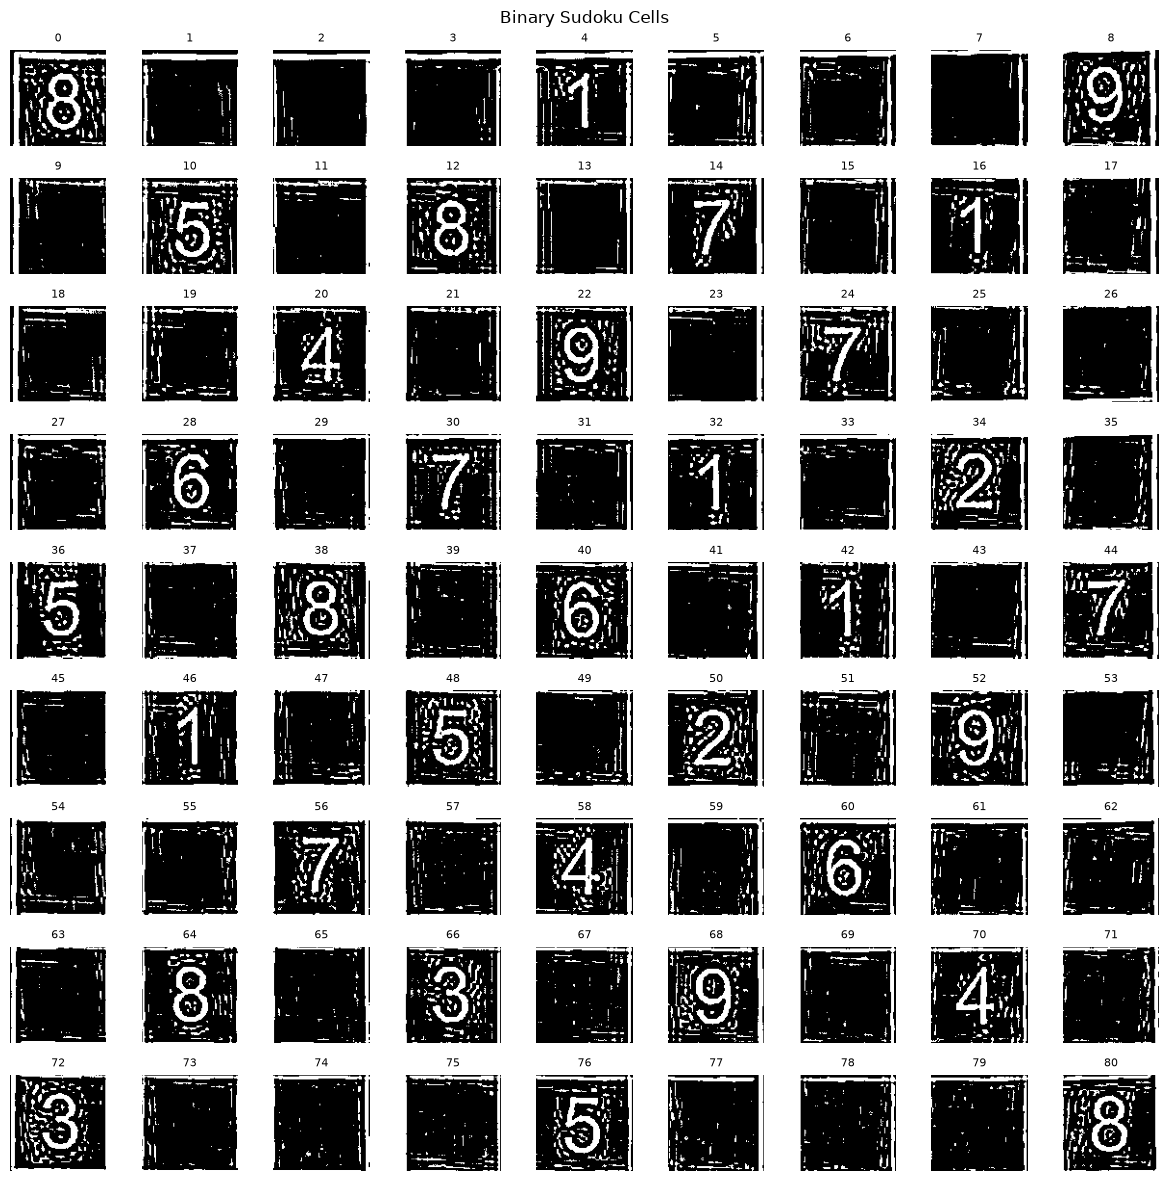

In [16]:
fig, axes = plt.subplots(9, 9, figsize=(12, 12))

for i in range(81):
    row = i // 9
    col = i % 9
    axes[row, col].imshow(binary_cells[i], cmap="gray")
    axes[row, col].set_title(str(i), fontsize=8)
    axes[row, col].axis("off")
    
plt.suptitle("Binary Sudoku Cells")
plt.tight_layout()
plt.show()

In [17]:
kernel = np.ones((3, 3), np.uint8)

cleaned_cells = []

for cell in binary_cells:
    opened = cv2.morphologyEx(cell, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
    cleaned_cells.append(closed)

print("Number of cleaned cells:", len(cleaned_cells))

Number of cleaned cells: 81


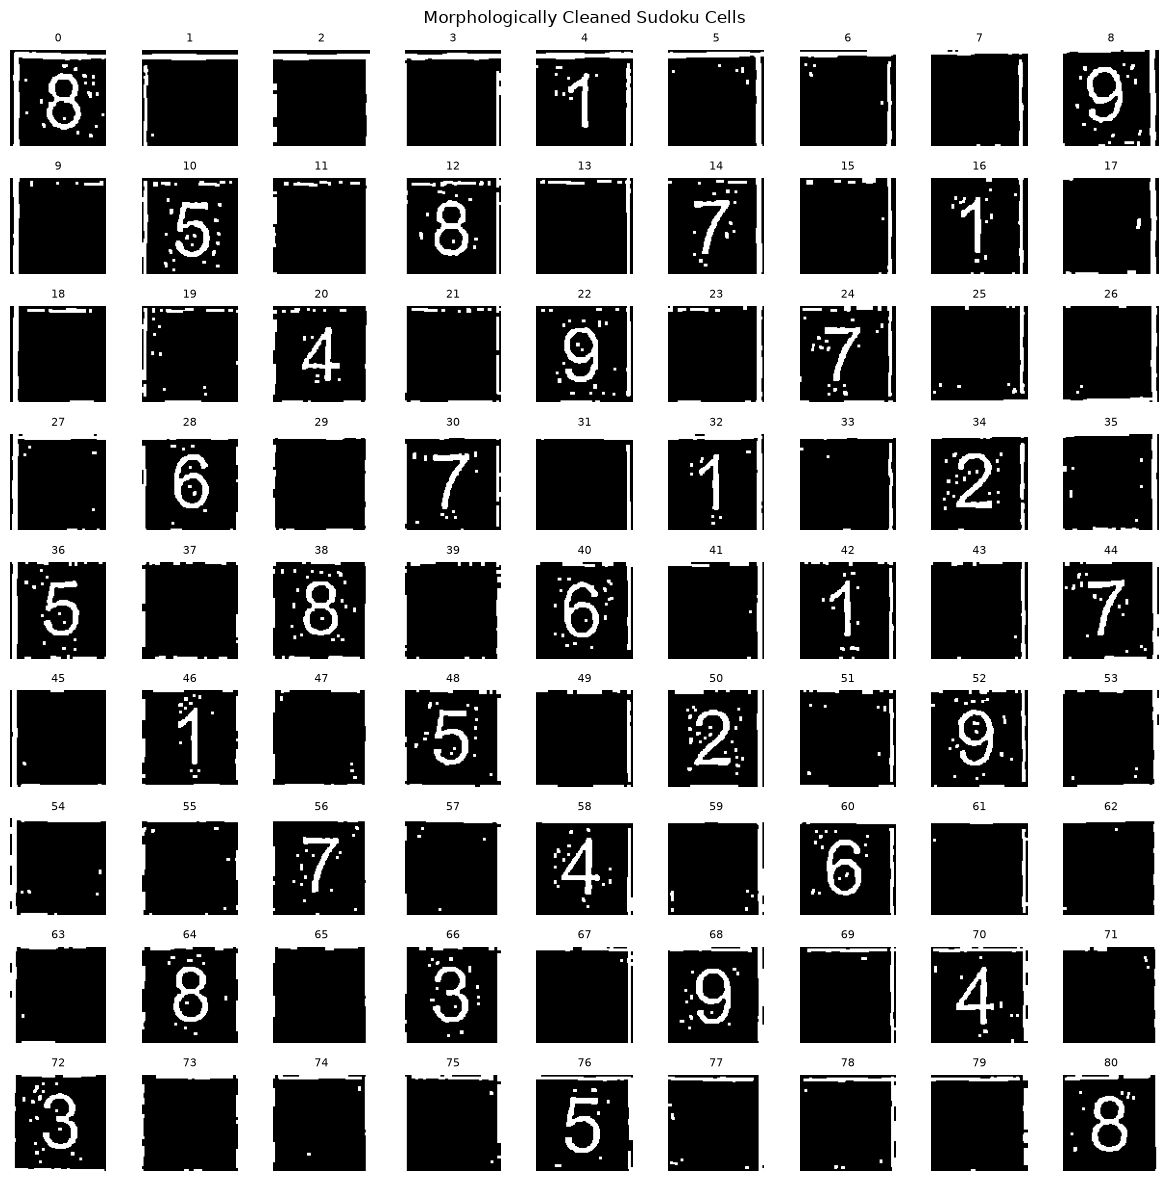

In [ ]:
fig, axes = plt.subplots(9, 9, figsize=(12, 12))

for i in range(81):
    row = i // 9
    col = i % 9
    axes[row, col].imshow(cleaned_cells[i], cmap="gray")
    axes[row, col].set_title(str(i), fontsize=8)
    axes[row, col].axis("off")

plt.suptitle("Morphologically Cleaned Sudoku Cells")
plt.tight_layout()
plt.show()